In [1]:
import cv2
from matplotlib import pyplot as plt 
import os
import numpy as np


## Lectura de DATOS 

### 1 -. Lista en BGR

In [2]:
#O una lista 
directory = "./imagenesTest/"

bgr_images = [cv2.imread(os.path.join(directory, file)) for file in os.listdir(directory)][80:110]   #solo 20 ****** (cambiar cuando quiera)


# if file.endswith('.png') si se quiere añadir__|^

### 2 -. Lista en GRAY (cvtColor) cv2.COLOR_BGRTOGRAY

In [3]:

gray_images = [cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) for image in bgr_images]

### 3-. Lista en RGB (cvtColor) 

In [4]:
rgb_images = [cv2.cvtColor(img, cv2.COLOR_BGR2RGB) for img in bgr_images]

### 4 -. Lista en HSV

In [5]:
hsv_images = [cv2.cvtColor(im, cv2.COLOR_BGR2HSV) for im in bgr_images]

## Mostramos

### Subplot con (única, bgr_images, gray_images, rgb_images, hsv_images)

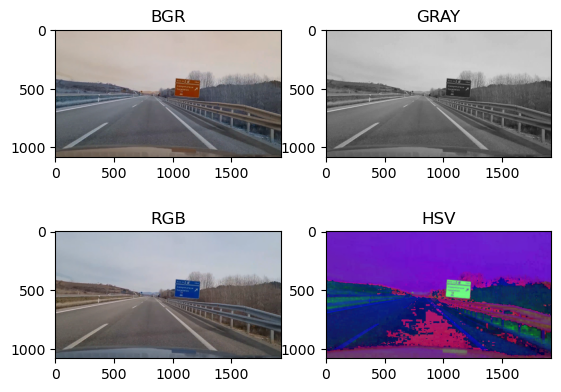

In [7]:
plt.subplot(2,2,1)
plt.imshow(bgr_images[0])
plt.title("BGR")

plt.subplot(2,2,2)
plt.imshow(gray_images[0], cmap="gray")
plt.title("GRAY")


plt.subplot(2,2,3)
plt.imshow(rgb_images[0])
plt.title("RGB")


plt.subplot(2,2,4)
plt.imshow(hsv_images[0])
plt.title("HSV")


plt.show()


## UMBRALIZADO POR COLOR

#### * paso previo

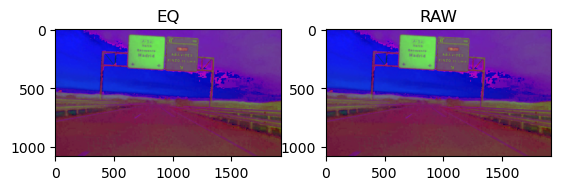

In [8]:
#creamos una copia de la lista(hsv_images) para luego equalizarla en el for y mejorar contarse 
eq_hsv_images = [np.copy(raw) for raw in hsv_images]

for pre_eq in eq_hsv_images:
    pre_eq = cv2.equalizeHist(pre_eq[:,:,2])

plt.subplot(1,2,1)
plt.imshow(eq_hsv_images[19])
plt.title("EQ")

plt.subplot(1,2,2)
plt.imshow(hsv_images[19])
plt.title("RAW")

plt.show()

In [9]:
print(len(hsv_images), hsv_images[0].shape)
print(len(eq_hsv_images), eq_hsv_images[0].shape)

22 (1080, 1920, 3)
22 (1080, 1920, 3)


### Máscara

In [10]:
def apply_mask(img, lower_blue, upper_blue):
    mask_aux  = cv2.inRange(img, lower_blue, upper_blue)
    return cv2.bitwise_and(img, img, mask=mask_aux)

In [11]:
#máscara
lower_blue = np.array([100,50,60])
upper_blue = np.array([130,255,255])

#100,70,70


In [12]:
print(len(hsv_images))

22


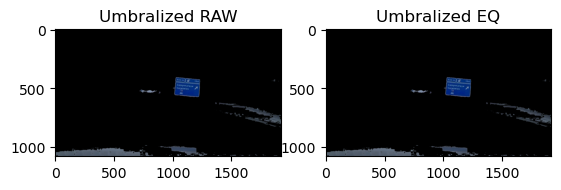

In [13]:
plt.subplot(1,2,1)
plt.imshow(cv2.cvtColor(cv2.cvtColor(apply_mask(hsv_images[0], lower_blue, upper_blue), cv2.COLOR_HSV2BGR), cv2.COLOR_BGR2RGB))
plt.title("Umbralized RAW")

plt.subplot(1,2,2)
plt.imshow(cv2.cvtColor(cv2.cvtColor(apply_mask(eq_hsv_images[0], lower_blue, upper_blue), cv2.COLOR_HSV2BGR), cv2.COLOR_BGR2RGB))
plt.title("Umbralized EQ")

plt.show()

In [14]:
#lista con imagenes umbralizadas, aplicando la mascara de azules en formato GRAY
gray_thresholded_images = [cv2.cvtColor((cv2.cvtColor(apply_mask(img, lower_blue, upper_blue), cv2.COLOR_HSV2BGR)),cv2.COLOR_BGR2GRAY) for img in hsv_images]

In [15]:
#lista con imagenes equalizadas y umbralizadas en GRAY
eq_gray_thresholded_images = [cv2.cvtColor((cv2.cvtColor(apply_mask(eq_img, lower_blue, upper_blue), cv2.COLOR_HSV2BGR)),cv2.COLOR_BGR2GRAY) for eq_img in eq_hsv_images]

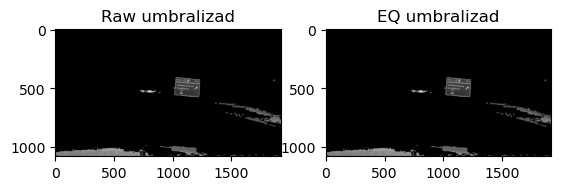

In [16]:
plt.subplot(1,2,1)
plt.imshow(gray_thresholded_images[0], cmap="gray")
plt.title("Raw umbralizad")

plt.subplot(1,2,2)
plt.imshow(eq_gray_thresholded_images[0], cmap="gray")
plt.title("EQ umbralizad")

plt.show()

In [17]:
#INICIALIZAMOS MSER

mser = cv2.MSER_create(delta=5, min_area=1000, max_area=40000, max_variation=0.9, min_diversity=0.1)

### FUNC: obtener lista con regiones de lista de imágenes

In [22]:
def getRegions(hsvs):
    allRegions = []
    for hsv in hsvs:
        _, boundingBoxes = mser.detectRegions(hsv)
        allRegions.append(boundingBoxes)
    return allRegions


### FUNC: agrupar regiones recibidas por parámetros, los rectangulos qeu considere iguales los agrupa en 1

In [23]:
def groupRegions(list_boxes):
    groupped_regions = []
    for boxes in list_boxes:
        groupped_rects, _ = cv2.groupRectangles(boxes, 1, eps=0.05)
        groupped_regions.append(groupped_rects)

        
    return groupped_regions

### FUNC: pintar lista de regiones en la lista de imagenes del formato deseado

In [24]:
def drawRegions(images_list, all_regions):
    for img, regs in zip(images_list, all_regions):
        for region in regs:
            x, y, w, h = region
            aspect_ratio = float(w) / h
            if 0.5 < aspect_ratio < 4:
                if w < 500:
                    if h < 500:
                        area = h * w
                        cv2.rectangle(img, (x,y), (x+w, y+h), (0,255,0), 2)

In [25]:
#creamos una copia de rgb_images, sobre las que pintaremos las regiones detectadas de eq_gray_thresholded_images, que son las que mser necesita, ya estan procesadas
copia_aux_rgbc = [np.copy(rgbi) for rgbi in rgb_images]


In [26]:
#pintamos todas las regiones detectadas en cada foto de la lista
drawRegions(copia_aux_rgbc, groupRegions(getRegions(eq_gray_thresholded_images)))

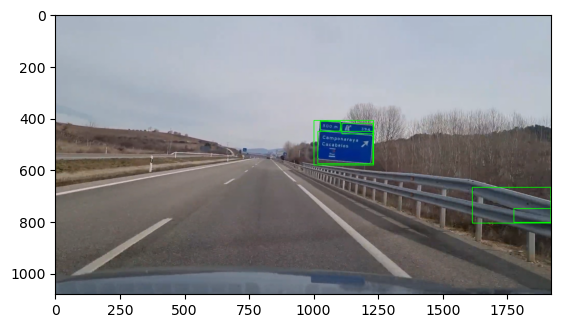

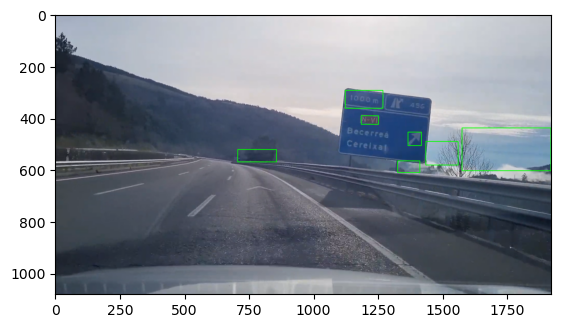

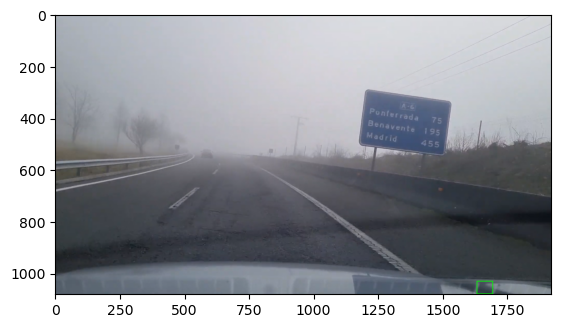

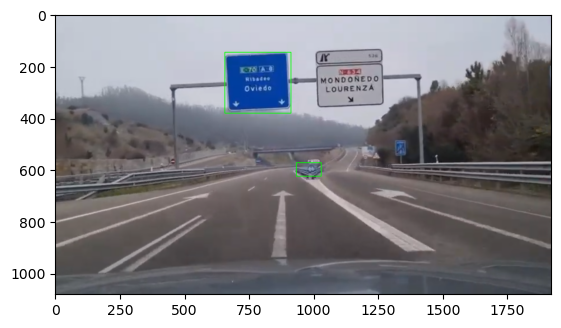

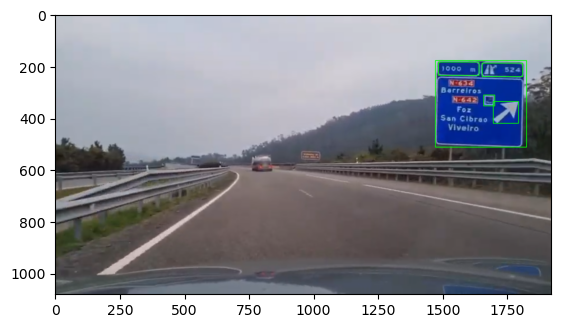

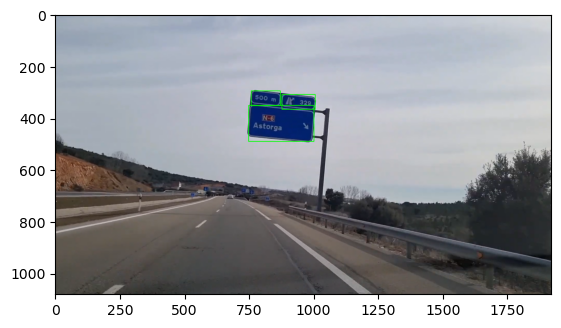

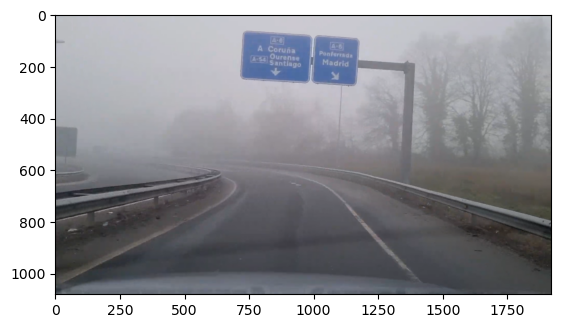

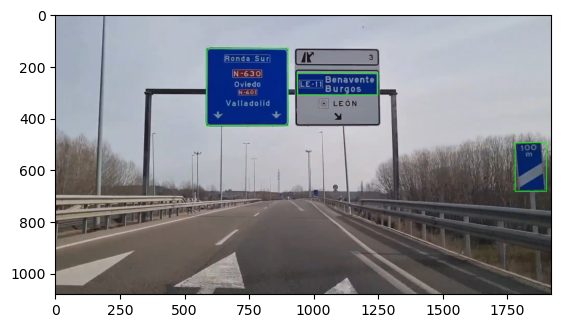

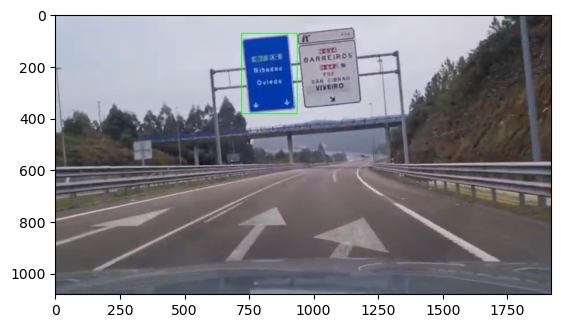

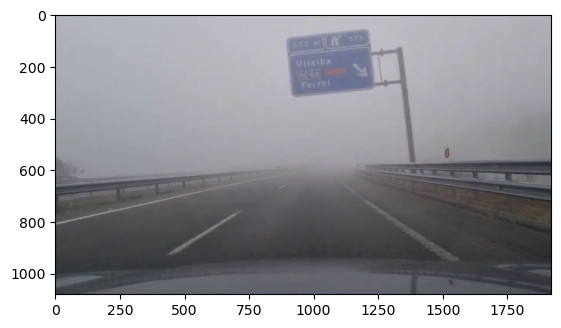

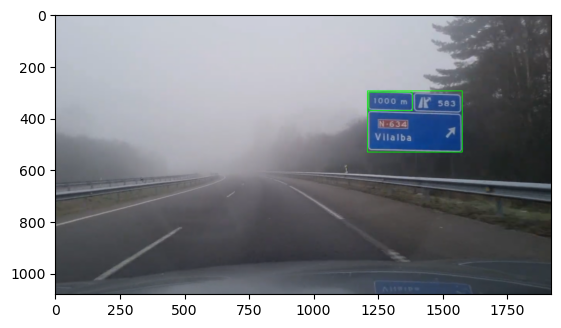

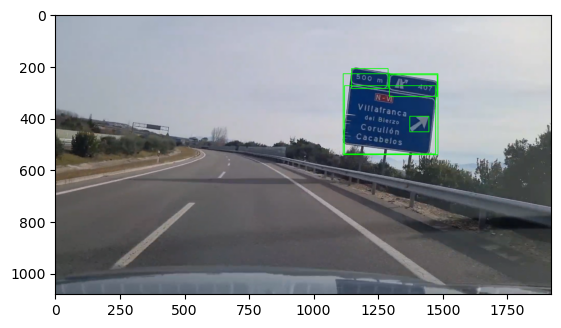

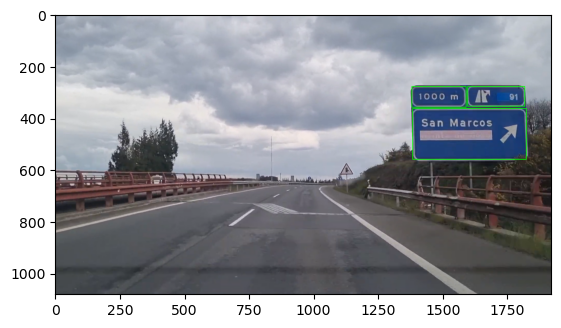

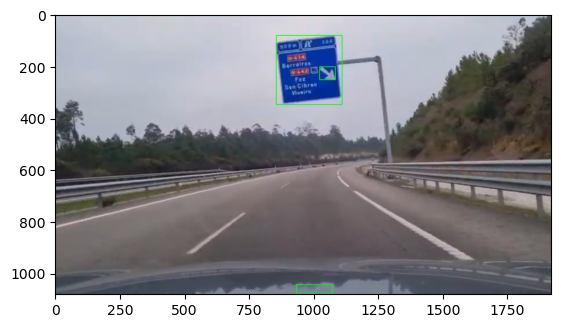

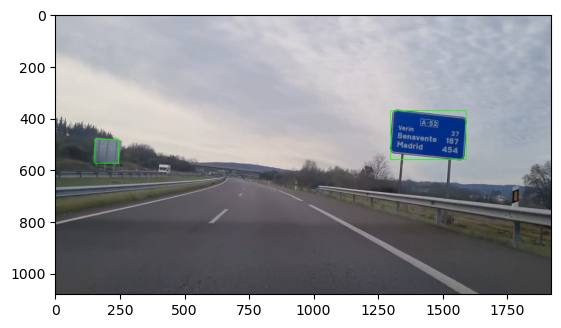

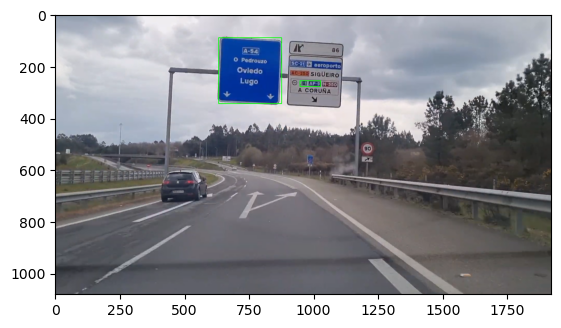

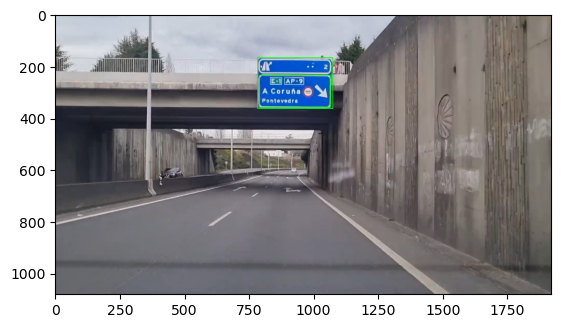

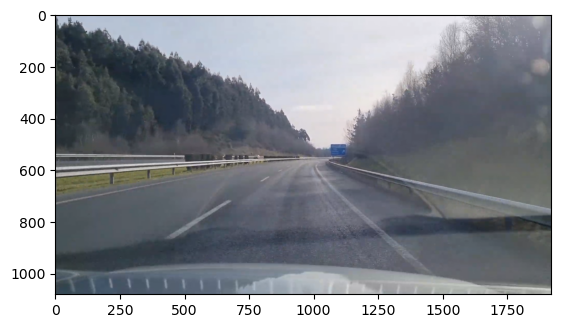

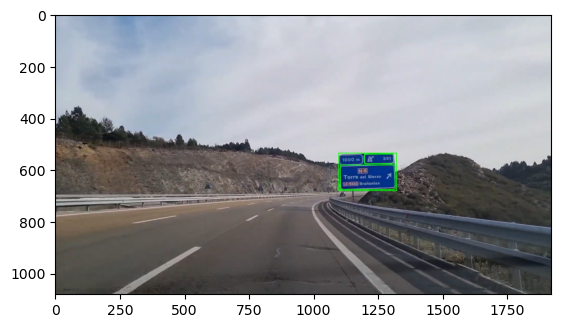

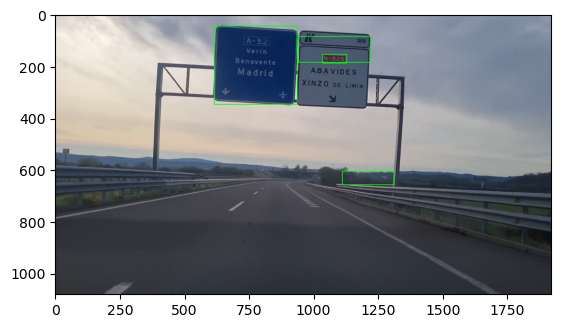

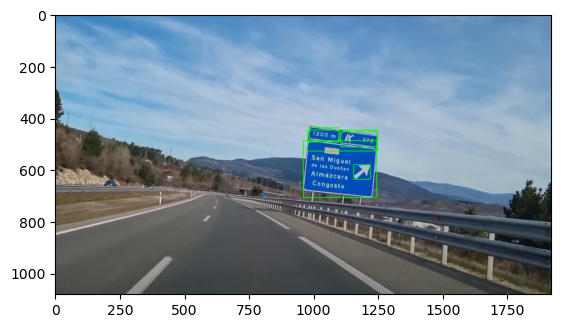

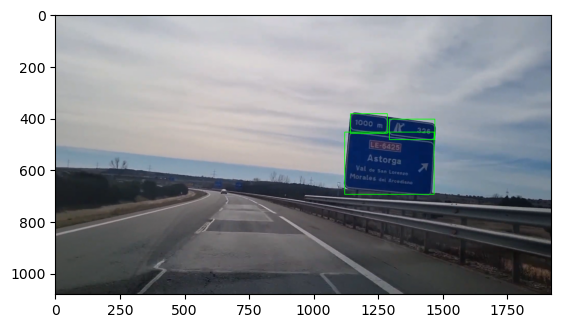

In [27]:
for imagen_rgb in copia_aux_rgbc:
    plt.imshow(imagen_rgb)
    plt.show()